# Задание 4.13
## Формула полной вероятности: корзина с биномиальным числом белых шаров

### Условие:
В корзину с $n$ шарами опускают белый шар. Найдите вероятность того, что извлечённый шар окажется белым, если первоначальное число белых шаров в корзине имеет биномиальное распределение с параметрами $n$ и $p$. Решите задачу в общем случае и для $n=10$, $p=\frac13$.

### Теория:
**Формула полной вероятности:** если $H_0,\dots,H_n$ — полная группа несовместных событий (гипотез), то $\mathbb P(A)=\sum_k\mathbb P(H_k)\mathbb P(A|H_k)$.

### Решение:
Гипотеза $H_k$: «первоначально в корзине $k$ белых шаров из $n$». По условию
$$\mathbb P(H_k)=C_n^kp^kq^{n-k},\qquad q=1-p,\ k=0,\dots,n .$$
После добавления белого шара в корзине $n+1$ шаров, из них $k+1$ белых. «Наудачу» извлечённый шар белый с вероятностью $\mathbb P(A|H_k)=\dfrac{k+1}{n+1}$. По формуле полной вероятности
$$\mathbb P(A)=\sum_{k=0}^nC_n^kp^kq^{n-k}\,\frac{k+1}{n+1}=\frac{\mathbb E K+1}{n+1}=\boxed{\frac{np+1}{n+1}}\qquad(K\sim\mathrm{Bin}(n,p),\ \mathbb EK=np).$$
**Частный случай** $n=10$, $p=\frac13$: 
$$\mathbb P(A)=\frac{10/3+1}{11}=\frac{13/3}{11}=\frac{13}{33}\approx0{,}3939 .$$

> **Замечание о листке.** В листке в качестве ответа указано $0{,}15625$. При $n=10$, $p=\frac13$ такое значение не получается (проверено точным суммированием и моделированием ниже). Число $0{,}15625=\frac{5}{32}$ даёт формула $\frac{np+1}{n+1}$ при $n=15$, $p=0{,}1$ (т. е. $\frac{2{,}5}{16}$) — возможно, в ответе перепутаны параметры. Рекомендуется уточнить условие у преподавателя.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

In [2]:
def P_total(n, p):
    # Точная сумма формулы полной вероятности (дроби)
    p = Fraction(p); q = 1 - p
    return sum(comb(n, k)*p**k*q**(n - k)*Fraction(k + 1, n + 1) for k in range(n + 1))

n, p = 10, Fraction(1, 3)
print('суммирование по гипотезам:', P_total(n, p), '≈', float(P_total(n, p)))
print('формула (np+1)/(n+1)     :', (n*p + 1)/(n + 1))
for (n_, p_) in [(5, Fraction(1, 2)), (20, Fraction(3, 10)), (15, Fraction(1, 10))]:
    print(f'n = {n_:2d}, p = {str(p_):5s}:  сумма = {float(P_total(n_, p_)):.6f},  (np+1)/(n+1) = {float((n_*p_ + 1)/(n_ + 1)):.6f}')

суммирование по гипотезам: 13/33 ≈ 0.3939393939393939
формула (np+1)/(n+1)     : 13/33
n =  5, p = 1/2  :  сумма = 0.583333,  (np+1)/(n+1) = 0.583333
n = 20, p = 3/10 :  сумма = 0.333333,  (np+1)/(n+1) = 0.333333
n = 15, p = 1/10 :  сумма = 0.156250,  (np+1)/(n+1) = 0.156250


### Моделирование $N=10^6$ опытов: число белых $K\sim\mathrm{Bin}(n,p)$, добавляем белый шар, вытаскиваем шар

N = 1000000: p̂ = 0.394142;  точное 13/33 = 0.393939
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.3500000   4.39e-02   1.47e-01
     1000   0.3980000   4.06e-03   4.64e-02
    10000   0.3902000   3.74e-03   1.47e-02
   100000   0.3942400   3.01e-04   4.64e-03
  1000000   0.3941420   2.03e-04   1.47e-03


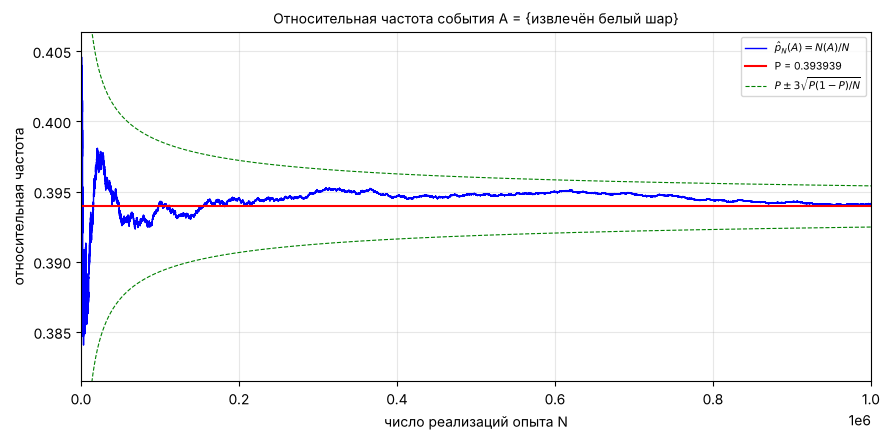

In [3]:
N = 1_000_000
K = rng.binomial(10, 1/3, size=N)                      # первоначальное число белых шаров
pick = rng.integers(0, 11, size=N)                     # номер извлечённого шара среди 11 (первые K+1 считаем белыми)
hit = pick < K + 1                                     # извлечён белый шар
P_ex = 13/33
print(f'N = {N}: p̂ = {hit.mean():.6f};  точное 13/33 = {P_ex:.6f}');  table(hit, P_ex)
fig, ax = plt.subplots(figsize=(9, 4.5)); plot_frequency(ax, hit, P_ex, 'Относительная частота события A = {извлечён белый шар}')
plt.tight_layout(); plt.savefig('task_4_13.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
Общий случай $\mathbb P(A)=\dfrac{np+1}{n+1}$; для $n=10$, $p=\frac13$: $\mathbb P(A)=\dfrac{13}{33}\approx0{,}3939$. (Значение $0{,}15625$ из листка соответствует, например, $n=15$, $p=0{,}1$ — см. замечание.)